## CNN Model - Face Mask Detection System

In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np
import matplotlib.pyplot as plt

### Loading the Dataset and Visualize

with_mask:  
without_mask:  
Total: 

In [2]:
DATASET_PATH = "dataset"
BATCH_SIZE = 32             # Number of images to process in a batch
IMG_SIZE = (128, 128)       # Resize images to this size

In [3]:
# 80% for training, 20% for testing

train_dataset = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split = 0.2,
    subset = "training",
    seed = 123,
    image_size = IMG_SIZE,
    batch_size = BATCH_SIZE,
    label_mode = "binary"   # Encodes labels as 0 and 1
)

test_dataset = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split = 0.2,
    subset = "validation",
    seed = 123,
    image_size = IMG_SIZE,
    batch_size = BATCH_SIZE,
    label_mode = "binary"
)

Found 7553 files belonging to 2 classes.
Using 6043 files for training.
Found 7553 files belonging to 2 classes.
Using 1510 files for validation.


In [4]:
class_names = train_dataset.class_names
print("Class names:", class_names)

Class names: ['with_mask', 'without_mask']


In [5]:
# Display the shape of the training and test data
for image_batch, label_batch in train_dataset.take(1):
    print("Training images batch shape:", image_batch.shape)    # batch_size, img_height, img_width, num_channels
    print("Training labels batch shape:", label_batch.shape)    # 32 labels (one for each image in the batch)

for image_batch, label_batch in test_dataset.take(1):
    print("Test images batch shape:", image_batch.shape)
    print("Test labels batch shape:", label_batch.shape)

Training images batch shape: (32, 128, 128, 3)
Training labels batch shape: (32, 1)
Test images batch shape: (32, 128, 128, 3)
Test labels batch shape: (32, 1)


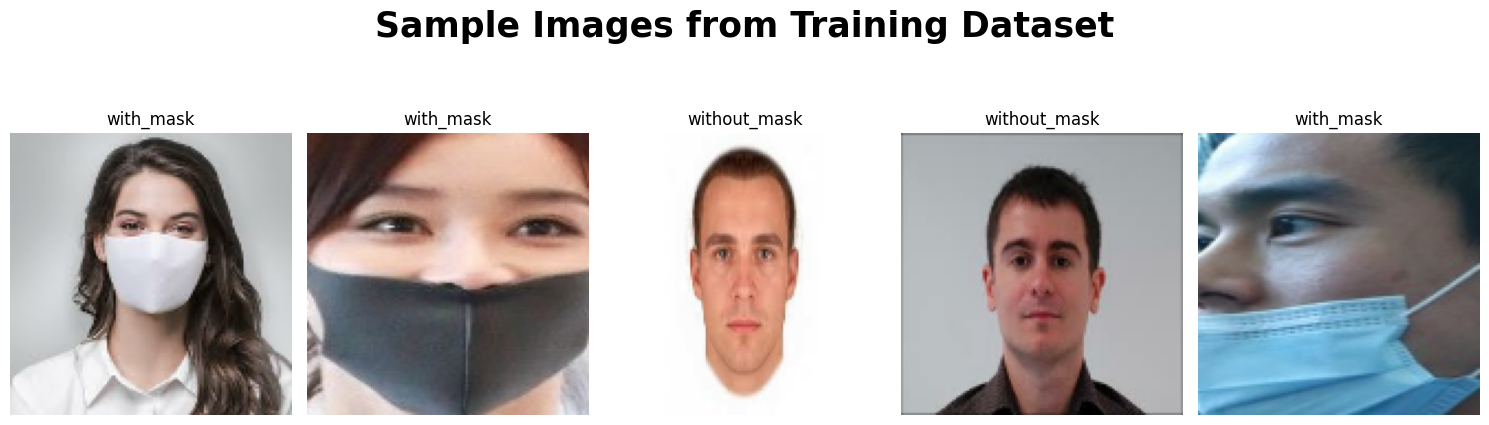

In [10]:
# Visualize five sample images
plt.figure(figsize=(15, 5))

for images, labels in train_dataset.take(1):
    for i in range(5):
        plt.subplot(1, 5, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))   # Convert tensor to uint8 for plotting
        plt.title(class_names[int(labels[i][0])])       # Use the label (0 or 1) to get the correct class name
        
        plt.suptitle("Sample Images from Training Dataset", fontsize=25, fontweight='bold')
        plt.axis("off")
        plt.tight_layout()  # Adjust the spacing between subplots

plt.show()

### Data Preprocessing and Augmentation

In [ ]:
data_augmentation_and_preprocessing = tf.keras.Sequential([
    # Resize images to a fixed size
    layers.Resizing(IMG_SIZE[0], IMG_SIZE[1]),

    # Normalize pixel values between 0 and 1
    layers.Rescaling(1./255),

    # Applying basic data augmentation (flipping and rotation)
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1)  # Rotate images by up to 10%
])

print("Preprocessing and augmentation pipeline created successfully.")

Preprocessing and augmentation pipeline created successfully.


### Create, Train, and Save the CNN

In [ ]:
# Create the Convolutional Neural Network (CNN) model
model = models.Sequential([
    # Preprocessing/Augmentation Block
    data_augmentation_and_preprocessing,

    # First Convolutional Block
    layers.Conv2D(32, (3, 3), activation='relu'),   # 32 filters, 3x3 kernel size, ReLU activation
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Second Convolutional Block
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Flatten and Fully Connected Layers
    layers.Flatten(),
    layers.Dense(128, activation='relu'),

    # Output Layer (1 node with Sigmoid for binary classification)
    layers.Dense(1, activation='sigmoid')
])

In [ ]:
# Compile the model
model.compile(
    optimizer = 'adam',
    loss = 'binary_crossentropy',
    metrics = ['accuracy']
)

In [ ]:
from keras.applications.vgg16 import VGG16
from keras import Sequential
from keras.layers import Dense

vgg = VGG16()
vgg.summary()

model = Sequential()

for layer in vgg.layers[:-1]: # last layer is the output layer, we will add our own output layer
    model.add(layer)

# freez the layers, so in the train the wieights doesn't update
for layer in model.layers:
    layer.trainable = False

model.summary()

model.add(Dense(1, activation='sigmoid'))
model.summary()


model.compile(optimizer='Adam', loss='binary_crossentropy', metrics=['accuracy'])
# model.fit(X_train, y_train, epoch=5, validation_data=(X_test, y_test))

### Testing the CNN Model